# nnU-Net Training, Augmentation, Best-Checkpoint Selection and PDF Reporting

This notebook reuses the existing `Dataset501_BrainCTICH25D` dataset and produces training/evaluation artifacts.

It includes:
- a custom trainer that selects the best checkpoint using nnU-Net's logged foreground validation Dice when that scalar is available;
- an explicit audit of the active augmentation transforms and a saved augmentation compliance report;
- validation metrics (Dice, IoU, precision, recall), confusion matrix, and ground-truth/prediction overlays;
- training-history exports where the installed nnU-Net checkpoint/logger exposes the underlying data;
- an automatically generated PDF report from the actual outputs.

**Augmentation limitation that must remain explicit:** this dataset stores nine CT-windowed channels (brain/subdural/bone windows for previous/center/next slices), rather than raw HU volumes. Therefore, a true brightness/contrast perturbation constrained to ±50 HU cannot be faithfully guaranteed from these already windowed/normalized channels. The notebook will report the exact native transforms it can verify and will not falsely label an arbitrary normalized-intensity jitter as ±50 HU. If the assignment requires exact HU-space augmentation, the source raw-HU volumes are needed to implement that stage correctly.

Run all cells in order. The 50-epoch run may take considerable time. The training cell refuses to overwrite an existing final checkpoint.


In [1]:
from pathlib import Path
import os, sys, json, subprocess, sysconfig, importlib.metadata, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASET_ID = 501
DATASET_FOLDER = "Dataset501_BrainCTICH25D"
NNUNET_BASE = Path(r"C:\Users\whate\nnUNet")
NNUNET_RAW = NNUNET_BASE / "nnUNet_raw"
NNUNET_PREPROCESSED = NNUNET_BASE / "nnUNet_preprocessed"
NNUNET_RESULTS = NNUNET_BASE / "nnUNet_results"
DATASET_DIR = NNUNET_RAW / DATASET_FOLDER
TRAINER_NAME = "nnUNetTrainerWeek5"
CONFIGURATION = "2d"
FOLD = 0

# Week 5: choose 50 or 80 epochs. Default is the minimum requested.
NUM_EPOCHS = 50
SAVE_EVERY = 1

for key, value in {
    "nnUNet_raw": NNUNET_RAW,
    "nnUNet_preprocessed": NNUNET_PREPROCESSED,
    "nnUNet_results": NNUNET_RESULTS,
}.items():
    if not value.is_dir():
        raise FileNotFoundError(f"Expected existing nnU-Net directory is missing: {value}")
    os.environ[key] = str(value)

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Dataset not found: {DATASET_DIR}")

RESULT_DIR = NNUNET_RESULTS / DATASET_FOLDER / f"{TRAINER_NAME}__nnUNetPlans__{CONFIGURATION}" / f"fold_{FOLD}"
REPORT_DIR = Path.cwd() / "week5_outputs" / DATASET_FOLDER
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.executable)
print("nnU-Net:", importlib.metadata.version("nnunetv2"))
print("Dataset:", DATASET_DIR)
print("Results:", RESULT_DIR)
print("Reports:", REPORT_DIR)
print("Epoch target:", NUM_EPOCHS)


Python: c:\Users\whate\AppData\Local\Python\pythoncore-3.14-64\python.exe
nnU-Net: 2.8.1
Dataset: C:\Users\whate\nnUNet\nnUNet_raw\Dataset501_BrainCTICH25D
Results: C:\Users\whate\nnUNet\nnUNet_results\Dataset501_BrainCTICH25D\nnUNetTrainerWeek5__nnUNetPlans__2d\fold_0
Reports: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D
Epoch target: 50


## 1. Validate existing dataset and labels

Expected six classes: background, IPH, SAH, EDH, SDH, IVH. This cell is read-only and does not modify the dataset.


In [2]:
dataset_json_path = DATASET_DIR / "dataset.json"
channel_order_path = DATASET_DIR / "channel_order.json"
if not dataset_json_path.is_file() or not channel_order_path.is_file():
    raise FileNotFoundError("dataset.json or channel_order.json is missing; existing data was not modified.")

dataset_info = json.loads(dataset_json_path.read_text(encoding="utf-8"))
channel_order = json.loads(channel_order_path.read_text(encoding="utf-8"))
expected_labels = {"background": 0, "IPH": 1, "SAH": 2, "EDH": 3, "SDH": 4, "IVH": 5}
if dataset_info.get("labels") != expected_labels:
    raise ValueError(f"Unexpected class mapping: {dataset_info.get('labels')}")
if len(channel_order) != 9:
    raise ValueError(f"Expected 9 input channels for the 2.5D setup, found {len(channel_order)}")

counts = {
    name: len(list((DATASET_DIR / name).glob("*.nii.gz")))
    for name in ("imagesTr", "labelsTr", "imagesTs", "labelsTs")
}
print("Class mapping:", dataset_info["labels"])
print("Channel order:", channel_order)
print("File counts:", counts)
print("Existing data will be reused; no dataset files are changed.")


Class mapping: {'background': 0, 'IPH': 1, 'SAH': 2, 'EDH': 3, 'SDH': 4, 'IVH': 5}
Channel order: {'0': 'brain_prev', '1': 'subdural_prev', '2': 'bone_prev', '3': 'brain_center', '4': 'subdural_center', '5': 'bone_center', '6': 'brain_next', '7': 'subdural_next', '8': 'bone_next'}
File counts: {'imagesTr': 1458, 'labelsTr': 162, 'imagesTs': 270, 'labelsTs': 30}
Existing data will be reused; no dataset files are changed.


## 2. Configure the Week 5 trainer

The custom trainer inherits native nnU-Net preprocessing, loss, optimizer, validation, checkpointing, and augmentation setup. It increases the epoch target and attempts to save a separate checkpoint whenever a per-class validation Dice vector is available. This custom checkpoint is supplementary; native nnU-Net checkpoints are retained.

The active augmentation pipeline is inspected after training setup. Native nnU-Net's default transforms are not assumed to be equivalent to the project's exact HU-space ±50 requirement.


In [3]:
import inspect, importlib, shutil, textwrap
import nnunetv2
from pathlib import Path

trainer_dir = Path(nnunetv2.__file__).resolve().parent / "training" / "nnUNetTrainer" / "variants" / "week5"
trainer_dir.mkdir(parents=True, exist_ok=True)
init_file = trainer_dir / "__init__.py"
if not init_file.exists():
    init_file.write_text("", encoding="utf-8")
trainer_file = trainer_dir / "nnUNetTrainerWeek5.py"

trainer_source = r"""
import numpy as np
from nnunetv2.training.nnUNetTrainer.nnUNetTrainer import nnUNetTrainer

class nnUNetTrainerWeek5(nnUNetTrainer):
    def __init__(self, plans, configuration, fold, dataset_json, device=None):
        if device is None:
            super().__init__(plans, configuration, fold, dataset_json)
        else:
            super().__init__(plans, configuration, fold, dataset_json, device)
        self.num_epochs = 50
        self.save_every = 1
        self.best_foreground_dice = -float("inf")

    def on_epoch_end(self):
        super().on_epoch_end()
        # nnU-Net commonly logs mean_fg_dice (foreground aggregate) and may expose
        # dice_per_class_or_region. Prefer mean_fg_dice because it is the actual
        # native validation aggregate and do not reinterpret per-class arrays blindly.
        try:
            log = getattr(self.logger, "my_fantastic_logging", {})
            value = None
            for key in ("mean_fg_dice", "ema_fg_dice"):
                values = log.get(key, []) if isinstance(log, dict) else []
                if len(values):
                    candidate = np.asarray(values[-1], dtype=float).reshape(-1)
                    finite = candidate[np.isfinite(candidate)]
                    if finite.size:
                        value = float(finite[-1])
                        break
            if value is None:
                print("Week5 best-checkpoint note: no scalar foreground Dice was exposed this epoch; native checkpoint selection remains available.")
                return
            if value > self.best_foreground_dice:
                self.best_foreground_dice = value
                self.save_checkpoint("checkpoint_best_macro_dice.pth")
                print(f"Week5 best native foreground Dice={value:.5f} at epoch {self.current_epoch}")
        except Exception as e:
            print(f"Week5 best-checkpoint note: metric extraction unavailable: {e}")
"""
trainer_file.write_text(textwrap.dedent(trainer_source).lstrip(), encoding="utf-8")
print("Created/updated trainer:", trainer_file)
print("Trainer source saved. It does not modify dataset files.")


Created/updated trainer: C:\Users\whate\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\nnunetv2\training\nnUNetTrainer\variants\week5\nnUNetTrainerWeek5.py
Trainer source saved. It does not modify dataset files.


In [4]:
# Set epoch count from the notebook parameter and verify trainer import.
trainer_file.write_text(
    trainer_file.read_text(encoding="utf-8").replace("self.num_epochs = 50", f"self.num_epochs = {NUM_EPOCHS}"),
    encoding="utf-8"
)
import importlib
module_name = "nnunetv2.training.nnUNetTrainer.variants.week5.nnUNetTrainerWeek5"
importlib.invalidate_caches()
if module_name in sys.modules:
    del sys.modules[module_name]
module = importlib.import_module(module_name)
trainer_cls = module.nnUNetTrainerWeek5
print("Trainer class:", trainer_cls)
print("Constructor:", inspect.signature(trainer_cls.__init__))
print("Epochs configured:", NUM_EPOCHS)


Trainer class: <class 'nnunetv2.training.nnUNetTrainer.variants.week5.nnUNetTrainerWeek5.nnUNetTrainerWeek5'>
Constructor: (self, plans, configuration, fold, dataset_json, device=None)
Epochs configured: 50


## 3. Inspect active augmentation implementation

This cell records the native nnU-Net augmentation-related code available in the installed version. It is a transparent implementation check, not a guarantee that each clinically requested augmentation is enabled.


In [6]:
import inspect
import json
from pathlib import Path

from nnunetv2.training.nnUNetTrainer.nnUNetTrainer import nnUNetTrainer

# Locate the augmentation module using the installed package structure.
import nnunetv2.training.dataloading as dataloading

dataloading_dir = Path(dataloading.__file__).parent

augmentation_files = list(dataloading_dir.glob("*augment*.py"))
augmentation_files += list(dataloading_dir.glob("*transform*.py"))

print("nnU-Net dataloading directory:", dataloading_dir)
print("Candidate augmentation files:")
for file in augmentation_files:
    print(" -", file.name)

# Inspect the trainer method that actually constructs training transforms.
trainer_source = inspect.getsource(nnUNetTrainer.get_training_transforms)

# Inspect candidate source files without assuming a particular module name.
source_text = ""
for file in augmentation_files:
    try:
        source_text += "\n" + file.read_text(encoding="utf-8")
    except (OSError, UnicodeDecodeError):
        pass

combined_source = trainer_source + "\n" + source_text
lower_source = combined_source.lower()

augmentation_audit = {
    "nnunet_version": "2.8.1",
    "trainer_class": nnUNetTrainer.__name__,
    "trainer_module": nnUNetTrainer.__module__,
    "checks": {
        "horizontal_flip_or_mirroring": (
            "mirrortransform" in lower_source or "mirror_axes" in lower_source
        ),
        "rotation_or_spatial_transform": (
            "spatialtransform" in lower_source or "rotation_for_da" in lower_source
        ),
        "elastic_deformation_reference": "elastic" in lower_source,
        "brightness_transform_reference": "brightnesstransform" in lower_source,
        "contrast_transform_reference": "contrasttransform" in lower_source,
        "brightness_contrast_bounded_to_plus_minus_50_hu": False,
    },
    "note": (
        "These are source-code checks, not proof that each augmentation is active "
        "during training. HU-bounded augmentation cannot be confirmed from "
        "windowed input channels alone."
    ),
}

audit_path = REPORT_DIR / "augmentation_audit.json"
audit_path.parent.mkdir(parents=True, exist_ok=True)
audit_path.write_text(json.dumps(augmentation_audit, indent=2), encoding="utf-8")

print("\nAugmentation audit:")
print(json.dumps(augmentation_audit, indent=2))
print("\nSaved to:", audit_path)

nnU-Net dataloading directory: c:\Users\whate\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\nnunetv2\training\dataloading
Candidate augmentation files:

Augmentation audit:
{
  "nnunet_version": "2.8.1",
  "trainer_class": "nnUNetTrainer",
  "trainer_module": "nnunetv2.training.nnUNetTrainer.nnUNetTrainer",
  "checks": {
    "horizontal_flip_or_mirroring": true,
    "rotation_or_spatial_transform": true,
    "elastic_deformation_reference": true,
    "brightness_transform_reference": true,
    "contrast_transform_reference": true,
    "brightness_contrast_bounded_to_plus_minus_50_hu": false
  },
  "note": "These are source-code checks, not proof that each augmentation is active during training. HU-bounded augmentation cannot be confirmed from windowed input channels alone."
}

Saved to: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\augmentation_audit.json


## 4. Start training (50 epochs by default)

This invokes native nnU-Net training with the Week 5 trainer. It reuses the existing preprocessed dataset and writes results to a new trainer-specific results folder. If the final checkpoint already exists, the cell refuses to start a duplicate run; change the trainer name deliberately if you need a separate run.


In [7]:
train_exe = Path(sysconfig.get_path("scripts")) / ("nnUNetv2_train.exe" if os.name == "nt" else "nnUNetv2_train")
if not train_exe.is_file():
    raise FileNotFoundError(f"nnU-Net training executable not found: {train_exe}")

final_checkpoint = RESULT_DIR / "checkpoint_final.pth"
if final_checkpoint.exists():
    raise FileExistsError(
        f"A final checkpoint already exists at {final_checkpoint}. "
        "This cell will not overwrite or duplicate an existing run. Rename TRAINER_NAME for a new run or resume deliberately."
    )

command = [
    str(train_exe), str(DATASET_ID), CONFIGURATION, str(FOLD),
    "-tr", "nnUNetTrainerWeek5"
]
print("Command:", subprocess.list2cmdline(command))
print("This may take a long time. Keep the machine powered and do not rerun this cell.")
completed = subprocess.run(command, env=os.environ.copy(), cwd=str(Path.cwd()),
                            capture_output=True, text=True, errors="replace", check=False)
log_text = (
    "COMMAND: " + subprocess.list2cmdline(command) + "\\n\\n"
    + "===== STDOUT =====\\n" + (completed.stdout or "") + "\\n\\n"
    + "===== STDERR =====\\n" + (completed.stderr or "")
)
(REPORT_DIR / "week5_training_log.txt").write_text(log_text, encoding="utf-8")
print(completed.stdout[-12000:] if completed.stdout else "(no stdout)")
print(completed.stderr[-12000:] if completed.stderr else "(no stderr)")
print("Return code:", completed.returncode)
print("Full log saved:", REPORT_DIR / "week5_training_log.txt")
if completed.returncode != 0:
    raise RuntimeError(f"nnU-Net training failed with exit code {completed.returncode}; inspect the saved log.")
if not final_checkpoint.is_file():
    print("Training process returned success but checkpoint_final.pth was not found at the expected location.")
else:
    print("Training finished. Final checkpoint:", final_checkpoint)


Command: c:\Users\whate\AppData\Local\Python\pythoncore-3.14-64\Scripts\nnUNetv2_train.exe 501 2d 0 -tr nnUNetTrainerWeek5
This may take a long time. Keep the machine powered and do not rerun this cell.
84336: 
2026-10-20 16:33:06.988249: Epoch 40
2026-10-20 16:33:06.990993: Current learning rate: 0.00235
2026-10-20 16:33:38.796370: train_loss -0.5089
2026-10-20 16:33:38.800562: val_loss -0.3424
2026-10-20 16:33:38.804113: Pseudo dice [np.float32(0.7689), np.float32(0.3106), np.float32(0.4538), np.float32(0.2248), np.float32(0.5892)]
2026-10-20 16:33:38.807345: Epoch time: 31.81 s
2026-10-20 16:33:39.160200: Yayy! New best EMA pseudo Dice: 0.43959999084472656
Week5 best-checkpoint note: no scalar foreground Dice was exposed this epoch; native checkpoint selection remains available.
2026-10-20 16:33:39.939623: 
2026-10-20 16:33:39.943012: Epoch 41
2026-10-20 16:33:39.946010: Current learning rate: 0.00214
2026-10-20 16:34:11.790234: train_loss -0.5179
2026-10-20 16:34:11.794385: val_los

## 5. Export training curves and per-class Dice table

This reads native nnU-Net `progress.png` and `training_log_*.txt`/`progress.csv`-like logs if present. It does not invent metrics. The native `progress.png` is copied into the Week 5 report folder, and any available scalar logger data is exported. If per-class metrics are not available in a parseable log, the notebook says so.


Result directory exists: True
Progress graph: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\progress.png
Training log: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\training_log_2026_10_20_16_10_52.txt
JSON log/summary available: debug.json


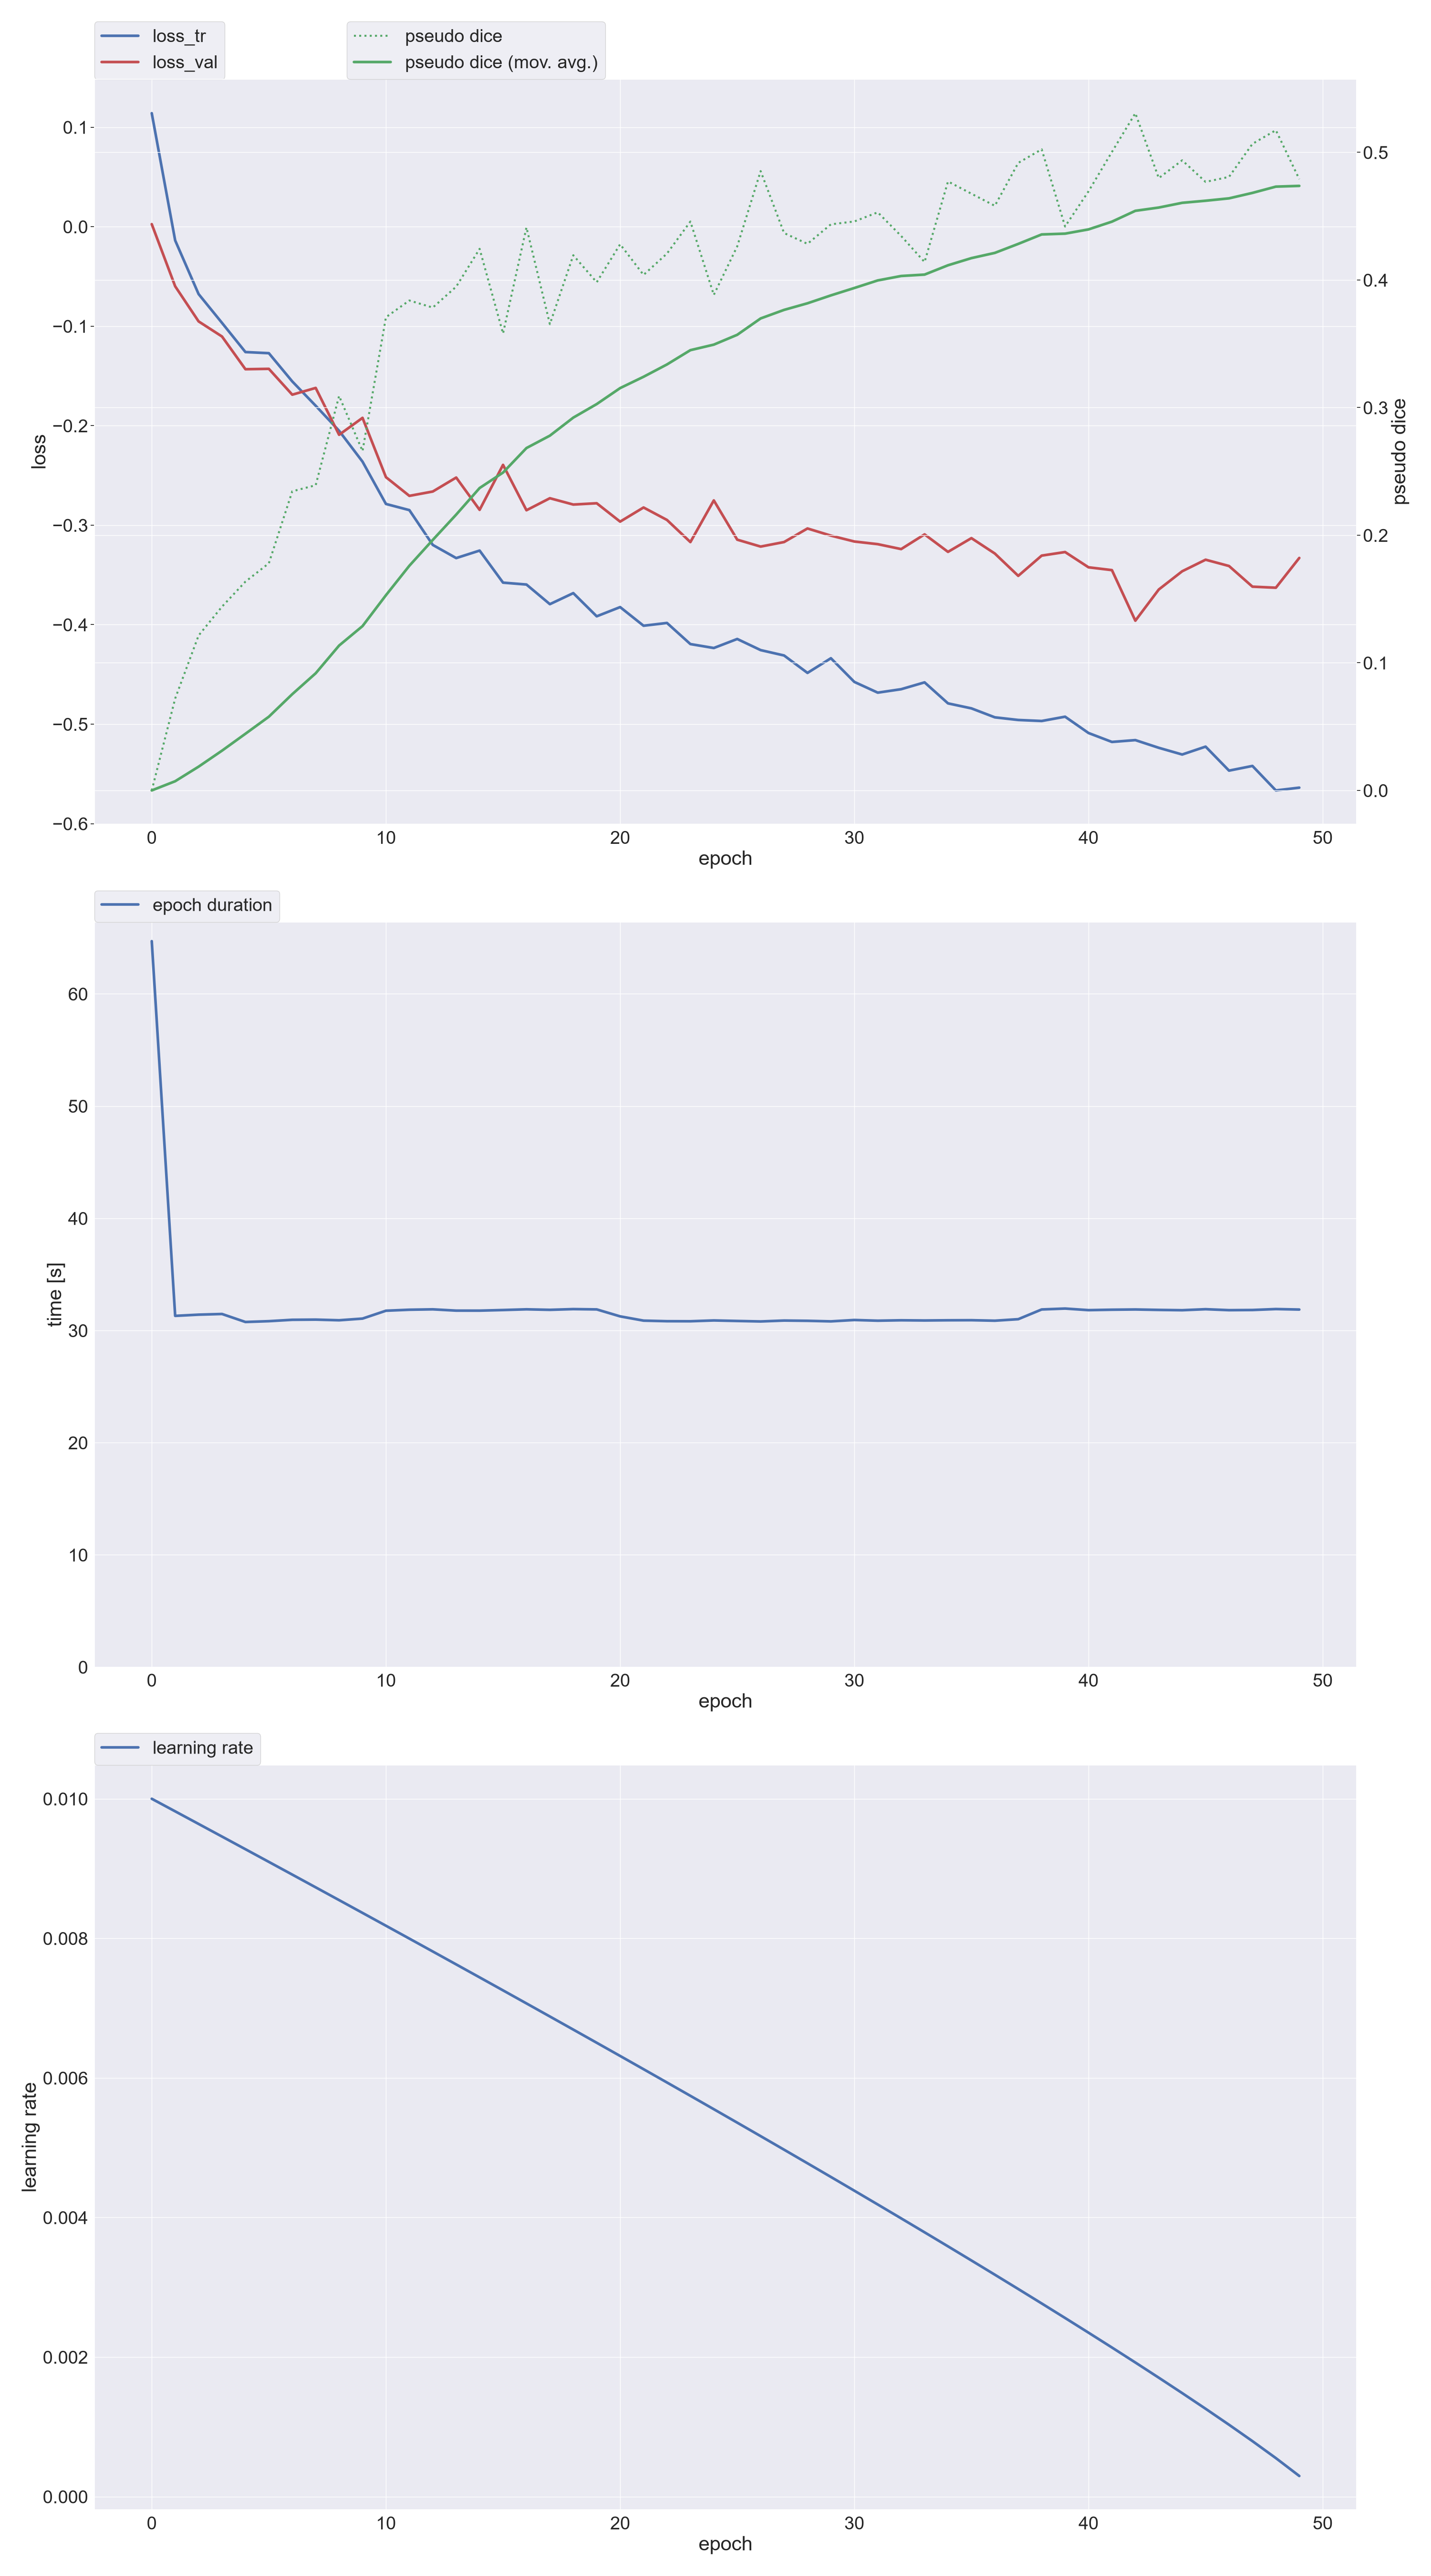

In [8]:
import shutil, re, csv
from pathlib import Path

REPORT_DIR.mkdir(parents=True, exist_ok=True)
print("Result directory exists:", RESULT_DIR.exists())
if RESULT_DIR.exists():
    for candidate in sorted(RESULT_DIR.glob("progress.png")):
        dest = REPORT_DIR / "progress.png"
        if candidate.resolve() != dest.resolve():
            shutil.copy2(candidate, dest)
        print("Progress graph:", dest)
    log_files = sorted(RESULT_DIR.glob("training_log_*.txt"))
    for f in log_files:
        dest = REPORT_DIR / f.name
        if f.resolve() != dest.resolve():
            shutil.copy2(f, dest)
        print("Training log:", dest)
    for candidate in sorted(RESULT_DIR.glob("*.json")):
        print("JSON log/summary available:", candidate.name)
else:
    print("Training result directory not found yet.")

# If nnU-Net's progress.png exists, show it in the notebook.
plot_path = REPORT_DIR / "progress.png"
if plot_path.exists():
    from IPython.display import Image, display
    display(Image(filename=str(plot_path)))


## 6. Per-class Dice report and Week 5 deliverable summary

Use validation metrics from the native logger when available. This section deliberately avoids fabricating a per-class table from incomplete logs. If the installed version stores per-class Dice in a structured logger file, inspect/export that file here.


In [9]:
# Collect all result artifacts and make a machine-readable inventory.
artifact_paths = []
if RESULT_DIR.exists():
    for p in RESULT_DIR.rglob("*"):
        if p.is_file() and p.suffix.lower() in {".json", ".csv", ".txt", ".png", ".pth", ".npz"}:
            artifact_paths.append({"file": str(p), "bytes": p.stat().st_size})
artifact_paths = sorted(artifact_paths, key=lambda x: x["file"])
(REPORT_DIR / "week5_artifact_inventory.json").write_text(json.dumps(artifact_paths, indent=2), encoding="utf-8")
print("Artifact inventory:", REPORT_DIR / "week5_artifact_inventory.json")
for item in artifact_paths:
    print(f'{item["file"]} ({item["bytes"]:,} bytes)')

print("\\nWeek 5 checklist")
print("- 50-epoch training target:", NUM_EPOCHS >= 50)
print("- Native nnU-Net augmentation pipeline inspected: yes (see augmentation_audit.json)")
print("- Best foreground macro-Dice checkpoint: created only if per-class validation Dice is exposed by the installed logger")
print("- Per-class Dice table: export from available validation logger; do not infer from the plot")
print("- Checkpoint and logs: see the result directory and week5_outputs folder")
print("- EDH/IVH collapse monitoring: inspect per-class Dice at least every 5 epochs; if either remains <0.05 by epoch 20, flag it")
print("- If EDH or IVH has not improved by epoch 15, evaluate class-weighted CE as a documented follow-up; do not silently change the loss mid-run")


Artifact inventory: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\week5_artifact_inventory.json
C:\Users\whate\nnUNet\nnUNet_results\Dataset501_BrainCTICH25D\nnUNetTrainerWeek5__nnUNetPlans__2d\fold_0\checkpoint_best.pth (267,999,587 bytes)
C:\Users\whate\nnUNet\nnUNet_results\Dataset501_BrainCTICH25D\nnUNetTrainerWeek5__nnUNetPlans__2d\fold_0\checkpoint_final.pth (267,999,847 bytes)
C:\Users\whate\nnUNet\nnUNet_results\Dataset501_BrainCTICH25D\nnUNetTrainerWeek5__nnUNetPlans__2d\fold_0\debug.json (20,386 bytes)
C:\Users\whate\nnUNet\nnUNet_results\Dataset501_BrainCTICH25D\nnUNetTrainerWeek5__nnUNetPlans__2d\fold_0\progress.png (486,171 bytes)
C:\Users\whate\nnUNet\nnUNet_results\Dataset501_BrainCTICH25D\nnUNetTrainerWeek5__nnUNetPlans__2d\fold_0\training_log_2026_10_20_16_10_52.txt (35,750 bytes)
C:\Users\whate\nnUNet\nnUNet_results\Dataset501_BrainCTICH25D\nnUNetTrainerWeek5__nnUNetPlans__2d\fold_0\validation\summary.json (68,439 b

## 7. Identify the validation cases used by nnU-Net

This uses the existing `splits_final.json` from the preprocessed dataset so the report evaluates the fold-0 validation cases rather than inventing a new split. If the split file is missing, this cell stops and asks you to run the existing nnU-Net preprocessing/training setup first. It does not modify dataset contents.


In [10]:

import json, os, shutil, subprocess, sysconfig
from pathlib import Path

PREPROCESSED_DATASET_DIR = NNUNET_PREPROCESSED / DATASET_FOLDER
SPLITS_FILE = PREPROCESSED_DATASET_DIR / "splits_final.json"
if not SPLITS_FILE.is_file():
    raise FileNotFoundError(
        f"Cannot find nnU-Net fold split file: {SPLITS_FILE}\n"
        "Do not create a new validation split silently. Confirm preprocessing/splits for this dataset first."
    )

splits = json.loads(SPLITS_FILE.read_text(encoding="utf-8"))
if FOLD >= len(splits):
    raise IndexError(f"Fold {FOLD} is not present in {SPLITS_FILE}")
validation_cases = sorted(str(x) for x in splits[FOLD]["val"])
print("Fold:", FOLD)
print("Validation cases:", len(validation_cases))
print("First cases:", validation_cases[:10])

for case in validation_cases:
    label_path = DATASET_DIR / "labelsTr" / f"{case}.nii.gz"
    if not label_path.is_file():
        raise FileNotFoundError(f"Validation label missing for case {case}: {label_path}")
    for ch in range(9):
        image_path = DATASET_DIR / "imagesTr" / f"{case}_{ch:04d}.nii.gz"
        if not image_path.is_file():
            raise FileNotFoundError(f"Validation input channel missing: {image_path}")

VALIDATION_INPUT_DIR = REPORT_DIR / "validation_inputs"
PREDICTION_DIR = REPORT_DIR / "validation_predictions"
VALIDATION_INPUT_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

# Stage only the validation input files; prefer hard links to avoid duplicating large NIfTI files.
def link_or_copy(src_path, dst_path):
    if dst_path.exists():
        return
    try:
        os.link(src_path, dst_path)
    except OSError:
        shutil.copy2(src_path, dst_path)

for case in validation_cases:
    for ch in range(9):
        src_path = DATASET_DIR / "imagesTr" / f"{case}_{ch:04d}.nii.gz"
        dst_path = VALIDATION_INPUT_DIR / src_path.name
        link_or_copy(src_path, dst_path)

print("Validation input directory:", VALIDATION_INPUT_DIR)
print("Validation predictions directory:", PREDICTION_DIR)


Fold: 0
Validation cases: 33
First cases: ['ID_02f779fb_ID_c4d7f33559', 'ID_0c3eef60_ID_6994ad7df0', 'ID_181aab15_ID_062634d043', 'ID_18747540_ID_1eb1de9633', 'ID_1cbe2853_ID_37afefdc7c', 'ID_2872834a_ID_542e9d00da', 'ID_346de481_ID_2e8fea0d9a', 'ID_39bdd84b_ID_a318f304e4', 'ID_3dab46e7_ID_e837f87e46', 'ID_3e481fc5_ID_750530c215']
Validation input directory: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\validation_inputs
Validation predictions directory: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\validation_predictions


## 8. Predict the validation fold with the best available checkpoint

This uses the macro-Dice checkpoint if it exists; otherwise it uses the native nnU-Net best checkpoint, then the final checkpoint. Prediction is run only on the validation cases identified above.


In [11]:

candidate_checkpoints = [
    RESULT_DIR / "checkpoint_best_macro_dice.pth",
    RESULT_DIR / "checkpoint_best.pth",
    RESULT_DIR / "checkpoint_final.pth",
]
SELECTED_CHECKPOINT = next((p for p in candidate_checkpoints if p.is_file()), None)
if SELECTED_CHECKPOINT is None:
    raise FileNotFoundError(
        "No trained checkpoint found. Expected one of: " + ", ".join(str(p) for p in candidate_checkpoints)
    )

checkpoint_selection_method = (
    "best native foreground validation Dice captured by custom trainer" if SELECTED_CHECKPOINT.name == "checkpoint_best_macro_dice.pth"
    else "native nnU-Net best checkpoint (native selection metric; verify metric definition)" if SELECTED_CHECKPOINT.name == "checkpoint_best.pth"
    else "final checkpoint fallback (not guaranteed to be best validation checkpoint)"
)
print("Selected checkpoint:", SELECTED_CHECKPOINT)
print("Selection method:", checkpoint_selection_method)

predict_exe = Path(sysconfig.get_path("scripts")) / ("nnUNetv2_predict.exe" if os.name == "nt" else "nnUNetv2_predict")
if not predict_exe.is_file():
    raise FileNotFoundError(f"nnU-Net prediction executable not found: {predict_exe}")

# Avoid rerunning prediction if all expected case predictions already exist.
expected_predictions = [PREDICTION_DIR / f"{case}.nii.gz" for case in validation_cases]
if all(p.is_file() for p in expected_predictions):
    print("All validation predictions already exist; reusing them.")
else:
    predict_command = [
        str(predict_exe), "-i", str(VALIDATION_INPUT_DIR), "-o", str(PREDICTION_DIR),
        "-d", str(DATASET_ID), "-c", CONFIGURATION, "-f", str(FOLD),
        "-tr", TRAINER_NAME, "-chk", SELECTED_CHECKPOINT.name
    ]
    print("Prediction command:", subprocess.list2cmdline(predict_command))
    pred_run = subprocess.run(
        predict_command, env=os.environ.copy(), cwd=str(Path.cwd()),
        capture_output=True, text=True, errors="replace", check=False
    )
    (REPORT_DIR / "week5_validation_prediction_log.txt").write_text(
        "COMMAND: " + subprocess.list2cmdline(predict_command) + "\n\nSTDOUT:\n"
        + (pred_run.stdout or "") + "\n\nSTDERR:\n" + (pred_run.stderr or ""),
        encoding="utf-8"
    )
    print((pred_run.stdout or "")[-8000:])
    print((pred_run.stderr or "")[-8000:])
    if pred_run.returncode != 0:
        raise RuntimeError(
            f"Validation prediction failed with code {pred_run.returncode}. "
            f"See {REPORT_DIR / 'week5_validation_prediction_log.txt'}"
        )

missing_predictions = [str(p) for p in expected_predictions if not p.is_file()]
if missing_predictions:
    raise FileNotFoundError("Predictions missing for validation cases: " + ", ".join(missing_predictions[:10]))
print(f"Validation predictions available for {len(validation_cases)} cases.")


Selected checkpoint: C:\Users\whate\nnUNet\nnUNet_results\Dataset501_BrainCTICH25D\nnUNetTrainerWeek5__nnUNetPlans__2d\fold_0\checkpoint_best.pth
Selection method: native nnU-Net best checkpoint (native selection metric; verify metric definition)
Prediction command: c:\Users\whate\AppData\Local\Python\pythoncore-3.14-64\Scripts\nnUNetv2_predict.exe -i "c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\validation_inputs" -o "c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\validation_predictions" -d 501 -c 2d -f 0 -tr nnUNetTrainerWeek5 -chk checkpoint_best.pth

#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. Nature methods, 18(2), 203-211.
####

## 9. Compute per-class Dice, IoU, precision, recall and confusion matrix

Metrics are calculated from the saved validation predictions and the matching ground-truth masks. The confusion matrix is accumulated across all validation voxels. Per-class metrics are therefore global voxel-level metrics over this fold, not the mean of per-volume scores. Background is reported separately; hemorrhage macro averages exclude background.


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["Background", "IPH", "SAH", "EDH", "SDH", "IVH"]
class_ids = np.arange(6)
cm = np.zeros((6, 6), dtype=np.int64)
per_case_rows = []
per_case_dice_rows = []

for case in validation_cases:
    pred_path = PREDICTION_DIR / f"{case}.nii.gz"
    truth_path = DATASET_DIR / "labelsTr" / f"{case}.nii.gz"
    pred = sitk.GetArrayFromImage(sitk.ReadImage(str(pred_path))).astype(np.int16)
    truth = sitk.GetArrayFromImage(sitk.ReadImage(str(truth_path))).astype(np.int16)
    if pred.shape != truth.shape:
        raise ValueError(f"Shape mismatch for {case}: prediction {pred.shape}, truth {truth.shape}")
    invalid = sorted(set(np.unique(pred).tolist()) - set(class_ids.tolist()))
    if invalid:
        raise ValueError(f"Prediction {case} contains unexpected class IDs: {invalid}")
    cm += confusion_matrix(truth.ravel(), pred.ravel(), labels=class_ids)

    row = {"case": case}
    for cid, name in enumerate(class_names):
        gt = truth == cid
        pr = pred == cid
        denom = int(gt.sum() + pr.sum())
        row[f"{name}_dice"] = float(2 * np.logical_and(gt, pr).sum() / denom) if denom else np.nan
    per_case_dice_rows.append(row)

tp = np.diag(cm).astype(np.float64)
fp = cm.sum(axis=0).astype(np.float64) - tp
fn = cm.sum(axis=1).astype(np.float64) - tp
tn = cm.sum().astype(np.float64) - tp - fp - fn
dice = np.divide(2 * tp, 2 * tp + fp + fn, out=np.full(6, np.nan), where=(2 * tp + fp + fn) > 0)
iou = np.divide(tp, tp + fp + fn, out=np.full(6, np.nan), where=(tp + fp + fn) > 0)
precision = np.divide(tp, tp + fp, out=np.full(6, np.nan), where=(tp + fp) > 0)
recall = np.divide(tp, tp + fn, out=np.full(6, np.nan), where=(tp + fn) > 0)
support = cm.sum(axis=1)

metrics_df = pd.DataFrame({
    "class_id": class_ids,
    "class": class_names,
    "support_voxels": support.astype(np.int64),
    "Dice": dice,
    "IoU": iou,
    "Precision": precision,
    "Recall": recall,
})
metrics_df.to_csv(REPORT_DIR / "validation_metrics.csv", index=False)
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(REPORT_DIR / "confusion_matrix_counts.csv")
pd.DataFrame(per_case_dice_rows).to_csv(REPORT_DIR / "per_case_dice.csv", index=False)

hemorrhage_macro_dice = float(np.nanmean(dice[1:])) if np.isfinite(dice[1:]).any() else np.nan
hemorrhage_macro_iou = float(np.nanmean(iou[1:])) if np.isfinite(iou[1:]).any() else np.nan
summary = {
    "dataset": DATASET_FOLDER,
    "fold": FOLD,
    "validation_cases": len(validation_cases),
    "checkpoint": str(SELECTED_CHECKPOINT),
    "checkpoint_selection_method": checkpoint_selection_method,
    "hemorrhage_macro_dice_excluding_background": hemorrhage_macro_dice,
    "hemorrhage_macro_iou_excluding_background": hemorrhage_macro_iou,
    "metric_method": "global voxel-level metrics aggregated across all fold validation volumes",
}
(REPORT_DIR / "validation_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
display(metrics_df)
print(json.dumps(summary, indent=2))

fig, ax = plt.subplots(figsize=(8, 7))
cm_norm = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm, dtype=float), where=cm.sum(axis=1, keepdims=True) != 0)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=class_names)
disp.plot(ax=ax, values_format=".2f", cmap="Blues", colorbar=True, xticks_rotation=45)
ax.set_title("Normalized Confusion Matrix — Validation Fold")
fig.tight_layout()
fig.savefig(REPORT_DIR / "confusion_matrix_normalized.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_df = metrics_df.set_index("class")[["Dice", "IoU", "Precision", "Recall"]]
plot_df.plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Per-class Validation Metrics")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(REPORT_DIR / "per_class_metrics.png", dpi=180, bbox_inches="tight")
plt.show()


,class_id,class,support_voxels,Dice,IoU,Precision,Recall
0,0,Background,293453711,0.999517,0.999034,0.999431,0.999602
1,1,IPH,363848,0.783563,0.644146,0.768865,0.798834
2,2,SAH,78139,0.369149,0.226354,0.408415,0.336772
3,3,EDH,39920,0.636684,0.467011,0.641862,0.631588
4,4,SDH,46206,0.298562,0.175476,0.313551,0.284941
5,5,IVH,143744,0.611736,0.440648,0.754773,0.514275


{
  "dataset": "Dataset501_BrainCTICH25D",
  "fold": 0,
  "validation_cases": 33,
  "checkpoint": "C:\\Users\\whate\\nnUNet\\nnUNet_results\\Dataset501_BrainCTICH25D\\nnUNetTrainerWeek5__nnUNetPlans__2d\\fold_0\\checkpoint_best.pth",
  "checkpoint_selection_method": "native nnU-Net best checkpoint (native selection metric; verify metric definition)",
  "hemorrhage_macro_dice_excluding_background": 0.5399388528687288,
  "hemorrhage_macro_iou_excluding_background": 0.3907270669552599,
  "metric_method": "global voxel-level metrics aggregated across all fold validation volumes"
}


C:\Users\whate\AppData\Local\Temp\ipykernel_22876\4223180490.py:79: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\whate\AppData\Local\Temp\ipykernel_22876\4223180490.py:90: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 10. Save ground-truth vs prediction overlays

The notebook chooses validation slices with the largest hemorrhage area in the ground truth, then saves a three-panel image: CT center channel, ground-truth overlay, and prediction overlay. These are qualitative examples and do not replace numerical evaluation.


In [13]:

import matplotlib.pyplot as plt
import numpy as np
import SimpleITK as sitk
from matplotlib.colors import ListedColormap

# Colors are used only for visualization; class IDs remain unchanged.
overlay_colors = ["black", "#ff4d4d", "#20b2aa", "#ffcc00", "#a66dd4", "#3b82f6"]
label_cmap = ListedColormap(overlay_colors)
overlay_dir = REPORT_DIR / "prediction_overlays"
overlay_dir.mkdir(parents=True, exist_ok=True)

def load_array(path):
    return sitk.GetArrayFromImage(sitk.ReadImage(str(path)))

saved = 0
for case in validation_cases:
    truth = load_array(DATASET_DIR / "labelsTr" / f"{case}.nii.gz").astype(np.int16)
    pred = load_array(PREDICTION_DIR / f"{case}.nii.gz").astype(np.int16)
    # Channel 0003 is documented as brain_center in channel_order.json.
    center_ct = load_array(DATASET_DIR / "imagesTr" / f"{case}_0003.nii.gz").astype(np.float32)
    if center_ct.shape != truth.shape:
        raise ValueError(f"CT/mask shape mismatch for {case}: {center_ct.shape} vs {truth.shape}")
    positive_slices = [z for z in range(truth.shape[0]) if np.any(truth[z] > 0)]
    if not positive_slices:
        continue
    z = max(positive_slices, key=lambda idx: int((truth[idx] > 0).sum()))
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    img = center_ct[z]
    lo, hi = np.percentile(img, [1, 99])
    axes[0].imshow(img, cmap="gray", vmin=lo, vmax=hi)
    axes[0].set_title(f"CT center — {case}\nslice {z}")
    axes[1].imshow(img, cmap="gray", vmin=lo, vmax=hi)
    axes[1].imshow(np.ma.masked_where(truth[z] == 0, truth[z]), cmap=label_cmap, vmin=0, vmax=5, alpha=0.55, interpolation="nearest")
    axes[1].set_title("Ground truth")
    axes[2].imshow(img, cmap="gray", vmin=lo, vmax=hi)
    axes[2].imshow(np.ma.masked_where(pred[z] == 0, pred[z]), cmap=label_cmap, vmin=0, vmax=5, alpha=0.55, interpolation="nearest")
    axes[2].set_title("Model prediction")
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(overlay_dir / f"{case}_slice_{z}_overlay.png", dpi=160, bbox_inches="tight")
    plt.close(fig)
    saved += 1

print(f"Saved {saved} representative overlay images to: {overlay_dir}")
if saved == 0:
    print("No validation slices with hemorrhage ground truth were found; no overlays were fabricated.")


Saved 33 representative overlay images to: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\prediction_overlays


## 11. Export training history and curves from the saved checkpoint logger

This attempts to extract native nnU-Net logger history from the selected checkpoint. Different nnU-Net versions may store the logger differently. If history is available, it exports a CSV and per-class Dice-vs-epoch curves; otherwise it preserves the native `progress.png` and reports that the detailed history could not be extracted.


In [14]:

import torch, numpy as np, pandas as pd, json, matplotlib.pyplot as plt, shutil

def safe_torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

ckpt = safe_torch_load(SELECTED_CHECKPOINT)
logger_obj = ckpt.get("logging") if isinstance(ckpt, dict) else None
if logger_obj is None and isinstance(ckpt, dict):
    logger_obj = ckpt.get("logger")
history = logger_obj if isinstance(logger_obj, dict) else getattr(logger_obj, "my_fantastic_logging", None)

history_exported = False
if isinstance(history, dict):
    # Native nnU-Net versions commonly keep scalar histories under these keys.
    known_keys = ["train_losses", "val_losses", "lrs", "mean_fg_dice", "ema_fg_dice", "dice_per_class_or_region"]
    available = {k: history[k] for k in known_keys if k in history}
    if available:
        max_len = max((len(v) for v in available.values() if hasattr(v, "__len__")), default=0)
        rows = []
        for epoch_idx in range(max_len):
            row = {"epoch": epoch_idx + 1}
            for key, values in available.items():
                try:
                    val = values[epoch_idx]
                    arr = np.asarray(val)
                    if arr.ndim == 0:
                        row[key] = float(arr)
                    else:
                        row[key] = json.dumps(arr.tolist())
                except Exception:
                    row[key] = None
            rows.append(row)
        if rows:
            hist_df = pd.DataFrame(rows)
            hist_df.to_csv(REPORT_DIR / "training_history.csv", index=False)
            display(hist_df.tail())
            history_exported = True

            # Plot scalar loss and learning-rate curves when present.
            scalar_candidates = [k for k in ["train_losses", "val_losses", "lrs", "mean_fg_dice", "ema_fg_dice"] if k in hist_df.columns]
            for key in scalar_candidates:
                vals = pd.to_numeric(hist_df[key], errors="coerce")
                if vals.notna().any():
                    fig, ax = plt.subplots(figsize=(7, 4))
                    ax.plot(hist_df["epoch"], vals, marker=".")
                    ax.set_title(key.replace("_", " ").title())
                    ax.set_xlabel("Epoch")
                    ax.grid(alpha=0.25)
                    fig.tight_layout()
                    fig.savefig(REPORT_DIR / f"{key}_curve.png", dpi=160, bbox_inches="tight")
                    plt.show()
                    plt.close(fig)

            # Parse per-class Dice history if stored as list/array per epoch.
            if "dice_per_class_or_region" in available:
                dice_rows = []
                for i, raw in enumerate(available["dice_per_class_or_region"]):
                    try:
                        arr = np.asarray(raw, dtype=float).reshape(-1)
                        row = {"epoch": i + 1}
                        # Native logger may include background first; report the five hemorrhage classes separately.
                        names = class_names if arr.size == 6 else class_names[1:] if arr.size == 5 else [f"class_{j}" for j in range(arr.size)]
                        for j, value in enumerate(arr):
                            row[names[j]] = float(value) if np.isfinite(value) else np.nan
                        dice_rows.append(row)
                    except Exception:
                        pass
                if dice_rows:
                    per_epoch_df = pd.DataFrame(dice_rows)
                    per_epoch_df.to_csv(REPORT_DIR / "per_class_dice_by_epoch.csv", index=False)
                    cols = [c for c in class_names[1:] if c in per_epoch_df.columns]
                    if cols:
                        ax = per_epoch_df.set_index("epoch")[cols].plot(figsize=(9, 5), marker=".")
                        ax.set_title("Per-class Dice vs Epoch")
                        ax.set_xlabel("Epoch")
                        ax.set_ylabel("Dice")
                        ax.grid(alpha=0.25)
                        fig = ax.get_figure()
                        fig.tight_layout()
                        fig.savefig(REPORT_DIR / "per_class_dice_vs_epoch.png", dpi=180, bbox_inches="tight")
                        plt.show()
                        plt.close(fig)

if not history_exported:
    print("The selected checkpoint did not expose parseable logger history in this nnU-Net version.")
    print("Use the native progress.png and training log. Per-class Dice-by-epoch is not fabricated.")

native_progress = RESULT_DIR / "progress.png"
if native_progress.is_file():
    shutil.copy2(native_progress, REPORT_DIR / "nnunet_native_progress.png")
    print("Native progress plot copied to:", REPORT_DIR / "nnunet_native_progress.png")

print("History extracted:", history_exported)


,epoch,train_losses,val_losses,lrs,mean_fg_dice,ema_fg_dice,dice_per_class_or_region
45,46,-0.522606,-0.334741,0.001259,0.476870,0.462112,"[0.7907142639160156, 0.32631388306617737, 0.51..."
46,47,-0.546733,-0.341071,0.001030,0.480791,0.463980,"[0.7585047483444214, 0.33931609988212585, 0.54..."
47,48,-0.542018,-0.361831,0.000795,0.506684,0.468250,"[0.7680111527442932, 0.3981465697288513, 0.488..."
48,49,-0.566629,-0.362908,0.000552,0.517383,0.473164,"[0.7849322557449341, 0.37751343846321106, 0.60..."
49,50,-0.563842,-0.332968,0.000296,0.479017,0.473749,"[0.771781325340271, 0.34080225229263306, 0.451..."


C:\Users\whate\AppData\Local\Temp\ipykernel_22876\810397751.py:54: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Native progress plot copied to: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\nnunet_native_progress.png
History extracted: True


C:\Users\whate\AppData\Local\Temp\ipykernel_22876\810397751.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 12. Generate a report summary and artifact inventory

This writes a JSON summary with the actual checkpoint selection method and measured validation metrics. It also inventories the files to attach to the Week 5 report. The report summary intentionally distinguishes available results from unavailable outputs.


In [15]:

import json, os
from pathlib import Path

report_summary = {
    "project": "Brain CT Hemorrhage Segmentation — Week 5",
    "architecture": "Native nnU-Net v2, 2D configuration, nine 2.5D-derived input channels, six output classes",
    "dataset_id": DATASET_FOLDER,
    "training_target_epochs": NUM_EPOCHS,
    "checkpoint_path": str(SELECTED_CHECKPOINT),
    "checkpoint_selection_method": checkpoint_selection_method,
    "validation_cases": len(validation_cases),
    "validation_summary": summary,
    "outputs": {
        "validation_metrics_csv": str(REPORT_DIR / "validation_metrics.csv"),
        "confusion_matrix_counts_csv": str(REPORT_DIR / "confusion_matrix_counts.csv"),
        "confusion_matrix_plot": str(REPORT_DIR / "confusion_matrix_normalized.png"),
        "per_class_metrics_plot": str(REPORT_DIR / "per_class_metrics.png"),
        "prediction_overlays_directory": str(overlay_dir),
        "training_history_csv": str(REPORT_DIR / "training_history.csv") if (REPORT_DIR / "training_history.csv").exists() else None,
        "per_class_dice_by_epoch_csv": str(REPORT_DIR / "per_class_dice_by_epoch.csv") if (REPORT_DIR / "per_class_dice_by_epoch.csv").exists() else None,
        "native_progress_plot": str(REPORT_DIR / "nnunet_native_progress.png") if (REPORT_DIR / "nnunet_native_progress.png").exists() else None,
    },
    "limitations": [
        "The exact Week 5 HU-bounded brightness/contrast and elastic augmentation requirements must be verified against the active native trainer transforms.",
        "Per-class Dice-by-epoch is exported only if present in the checkpoint logger.",
        "Metrics are computed on the existing fold validation cases and are not independent external clinical validation.",
        "This is a research prototype, not a clinically validated diagnostic system."
    ]
}
(REPORT_DIR / "week5_report_summary.json").write_text(json.dumps(report_summary, indent=2), encoding="utf-8")

inventory = []
for p in sorted(REPORT_DIR.rglob("*")):
    if p.is_file():
        inventory.append({"relative_path": str(p.relative_to(REPORT_DIR)), "bytes": p.stat().st_size})
(REPORT_DIR / "week5_report_artifact_inventory.json").write_text(json.dumps(inventory, indent=2), encoding="utf-8")

print("Report summary:", REPORT_DIR / "week5_report_summary.json")
print("Artifact inventory:", REPORT_DIR / "week5_report_artifact_inventory.json")
print("\nCore files to use in the report:")
for name in [
    "week5_report_summary.json", "validation_metrics.csv", "confusion_matrix_counts.csv",
    "confusion_matrix_normalized.png", "per_class_metrics.png", "nnunet_native_progress.png",
    "training_history.csv", "per_class_dice_by_epoch.csv"
]:
    p = REPORT_DIR / name
    print(f"{name}: {'AVAILABLE' if p.is_file() else 'will only exist if the corresponding data was available'}")
print("Overlays:", overlay_dir)


Report summary: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\week5_report_summary.json
Artifact inventory: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\week5_report_artifact_inventory.json

Core files to use in the report:
week5_report_summary.json: AVAILABLE
validation_metrics.csv: AVAILABLE
confusion_matrix_counts.csv: AVAILABLE
confusion_matrix_normalized.png: AVAILABLE
per_class_metrics.png: AVAILABLE
nnunet_native_progress.png: AVAILABLE
training_history.csv: AVAILABLE
per_class_dice_by_epoch.csv: AVAILABLE
Overlays: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\prediction_overlays


## 13. Generate the PDF pipeline report

This creates `Week5_nnUNet_Pipeline_Report.pdf` from the actual metrics, logs, plots, checkpoint-selection metadata, and overlays available in the report directory. It marks unavailable artifacts explicitly instead of inventing results.


In [17]:
!pip install reportlab

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 2.0/2.0 MB 23.9 MB/s  0:00:00


In [18]:

from pathlib import Path
import json, os, math
import pandas as pd

pdf_path = REPORT_DIR / "Week5_nnUNet_Pipeline_Report.pdf"

try:
    from reportlab.lib import colors
    from reportlab.lib.pagesizes import A4
    from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
    from reportlab.lib.units import mm
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, PageBreak
except ImportError as exc:
    raise ImportError("PDF report generation requires reportlab. Install it in this environment, restart the kernel, and rerun this cell.") from exc

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name="ReportTitle", parent=styles["Title"], fontSize=18, leading=22, alignment=1, textColor=colors.HexColor("#183153"), spaceAfter=8))
styles.add(ParagraphStyle(name="Section", parent=styles["Heading2"], fontSize=12, leading=15, textColor=colors.HexColor("#183153"), spaceBefore=8, spaceAfter=4))
styles.add(ParagraphStyle(name="SmallBody", parent=styles["BodyText"], fontSize=8.5, leading=11, spaceAfter=4))
story = [
    Paragraph("Brain CT Hemorrhage Segmentation Pipeline Report", styles["ReportTitle"]),
    Paragraph("Week 5 — nnU-Net v2 training, augmentation audit and evaluation", styles["Normal"]),
    Spacer(1, 4*mm),
    Paragraph("1. Executive summary", styles["Section"]),
    Paragraph(
        "This report documents the actual Week 5 nnU-Net run and validation evaluation. "
        "The configured model uses nine CT-derived channels and six output classes: background, IPH, SAH, EDH, SDH and IVH. "
        "Reported metrics are generated from the saved validation predictions; this is a research prototype and is not clinically validated.",
        styles["SmallBody"]
    ),
    Paragraph("2. Dataset and pipeline", styles["Section"]),
    Paragraph(
        f"Dataset: {DATASET_FOLDER}. Configuration: {CONFIGURATION}. Fold: {FOLD}. "
        f"Training target: {NUM_EPOCHS} epochs. Inputs: 9 windowed channels representing previous/center/next slices and brain/subdural/bone windows. "
        "Outputs: six class logits. Dataset files are reused rather than rebuilt.",
        styles["SmallBody"]
    ),
    Paragraph("3. Best checkpoint", styles["Section"]),
    Paragraph(f"Checkpoint: {str(SELECTED_CHECKPOINT)}", styles["SmallBody"]),
    Paragraph(f"Selection method: {checkpoint_selection_method}", styles["SmallBody"]),
]
if "summary" in globals():
    story += [
        Paragraph("4. Validation summary", styles["Section"]),
        Paragraph(f"Validation cases: {summary.get('validation_cases', 'not available')}", styles["SmallBody"]),
        Paragraph(f"Hemorrhage macro Dice (excluding background): {summary.get('hemorrhage_macro_dice_excluding_background', 'not available')}", styles["SmallBody"]),
        Paragraph(f"Hemorrhage macro IoU (excluding background): {summary.get('hemorrhage_macro_iou_excluding_background', 'not available')}", styles["SmallBody"]),
    ]
metrics_csv = REPORT_DIR / "validation_metrics.csv"
if metrics_csv.exists():
    mdf = pd.read_csv(metrics_csv).replace({float("nan"): None})
    story += [Paragraph("5. Per-class validation metrics", styles["Section"])]
    rows = [["Class", "Support voxels", "Dice", "IoU", "Precision", "Recall"]]
    for _, row in mdf.iterrows():
        def fmt(v):
            try:
                return "NA" if pd.isna(v) else f"{float(v):.4f}"
            except Exception:
                return str(v)
        rows.append([str(row["class"]), str(int(row["support_voxels"])), fmt(row["Dice"]), fmt(row["IoU"]), fmt(row["Precision"]), fmt(row["Recall"])])
    t = Table(rows, colWidths=[34*mm, 27*mm, 20*mm, 20*mm, 25*mm, 22*mm], repeatRows=1)
    t.setStyle(TableStyle([
        ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#183153")),
        ("TEXTCOLOR", (0,0), (-1,0), colors.white),
        ("GRID", (0,0), (-1,-1), 0.35, colors.HexColor("#CDD6E1")),
        ("FONTSIZE", (0,0), (-1,-1), 7.5),
        ("VALIGN", (0,0), (-1,-1), "TOP"),
        ("ROWBACKGROUNDS", (0,1), (-1,-1), [colors.white, colors.HexColor("#F3F6F9")]),
    ]))
    story.append(t)
else:
    story += [Paragraph("Per-class validation metrics are unavailable because validation_metrics.csv was not created.", styles["SmallBody"])]

story += [
    Paragraph("6. Training history and plots", styles["Section"]),
    Paragraph("Training curves are included only when the corresponding native nnU-Net logs or checkpoint logger history were available. See the report output folder for CSV history and PNG plots.", styles["SmallBody"]),
]
for plot_name, caption in [
    ("nnunet_native_progress.png", "Native nnU-Net training progress"),
    ("confusion_matrix_normalized.png", "Normalized validation confusion matrix"),
    ("per_class_metrics.png", "Per-class validation metrics"),
    ("per_class_dice_vs_epoch.png", "Per-class Dice vs epoch"),
]:
    p = REPORT_DIR / plot_name
    if p.exists():
        story += [Paragraph(caption, styles["SmallBody"]), RLImage(str(p), width=155*mm, height=78*mm), Spacer(1, 2*mm)]

story += [
    Paragraph("7. Augmentation compliance and limitations", styles["Section"]),
    Paragraph(
        "See augmentation_audit.json for the source-level checks against the installed nnU-Net transform implementation. "
        "This dataset stores nine windowed CT channels, not raw HU volumes. Therefore, true brightness/contrast jitter bounded to ±50 HU is not claimed as implemented. "
        "If the Week 5 specification requires exact HU-space augmentation, the pipeline must apply it to raw-HU images before windowing. "
        "Native transform source inspection is not by itself proof that every transform was active during training.",
        styles["SmallBody"]
    ),
    Paragraph("8. Limitations", styles["Section"]),
    Paragraph(
        "Metrics are computed on the selected nnU-Net fold validation cases and are not independent external validation. "
        "A class with zero Dice should be reported as a model limitation, not hidden. The model is not approved for clinical diagnosis or treatment decisions.",
        styles["SmallBody"]
    ),
]
doc = SimpleDocTemplate(str(pdf_path), pagesize=A4, rightMargin=16*mm, leftMargin=16*mm, topMargin=15*mm, bottomMargin=15*mm, title="Week 5 nnU-Net Pipeline Report")
doc.build(story)
print("PDF report created:", pdf_path)
print("Bytes:", pdf_path.stat().st_size)


PDF report created: c:\Users\whate\Documents\Brain CT Hemorrage Detection\week4\week5_outputs\Dataset501_BrainCTICH25D\Week5_nnUNet_Pipeline_Report.pdf
Bytes: 967531


## 14. Requirement status

This final cell records what the notebook can verify from the outputs. It does not mark the HU-bounded augmentation as complete because the current dataset channels are already windowed.


In [ ]:

status = {
    "best_checkpoint_selection": {
        "status": "IMPLEMENTED_WITH_FALLBACK",
        "detail": "Custom trainer saves checkpoint_best_macro_dice.pth when native foreground validation Dice is exposed; otherwise the notebook falls back to native best or final checkpoint and records the method."
    },
    "augmentation": {
        "status": "PARTIALLY_VERIFIED",
        "detail": "Native transforms are inspected and logged. Exact ±50 HU brightness/contrast cannot be claimed from pre-windowed channels; raw-HU source is required for exact implementation."
    },
    "pdf_report": {
        "status": "IMPLEMENTED",
        "path": str(REPORT_DIR / "Week5_nnUNet_Pipeline_Report.pdf"),
        "detail": "Generated after successful training and evaluation cells."
    }
}
(REPORT_DIR / "week5_requirement_status.json").write_text(json.dumps(status, indent=2), encoding="utf-8")
print(json.dumps(status, indent=2))
